# Live demo

Three trained models on any photo, side by side. Predictions use the code and the checkpoints of the evaluation.

- New photo: change `IMAGE_PATH`, then run **Parameters**, **Photo**, **Predict** and **Show**. The models stay loaded.
- New threshold: change `THRESHOLD` in **Show** and run only that cell. Nothing is predicted again.
- EXIF orientation is applied when a photo is opened, so portrait phone photos are upright. HEIC is not supported, use JPG or PNG.
- The times depend on other GPU load and are not a benchmark. The scores of different models are not calibrated to each other.
- `SMOKE = True` uses the S = 320 checkpoints, one photo, and writes to `runs/smoke/demo`.

## Parameters

In [1]:
IMAGE_PATH = "dataset/manual-benchmark/originals/IMG_20261124_171919.jpg"  # file or folder
RUNS = ["yolo_s640", "maskrcnn_s640", "m2f_s640"]
SCORE_THRESHOLD = 0.25
OUT_DIR = "results/demo"
SMOKE = False

## Load models

Once per session.

In [2]:
%config InlineBackend.figure_formats = ['jpeg']
import matplotlib.pyplot as plt
import pandas as pd

from iiss import demo

pd.set_option("display.max_rows", 100, "display.max_colwidth", 90, "display.width", 200)
if SMOKE:
    RUNS = [r.replace("_s640", "_s320").replace("_s960", "_s320") for r in RUNS]
    OUT_DIR = "runs/smoke/demo"
models = demo.load_models(RUNS)
names = demo.category_names()
print(*models, sep="\n")

c:\Users\Syauqi Nabil\Lectures\University\Semester 5\Computer Vision\Task\Instance Segmentation\indoor-instance-seg-shift\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 554/554 [00:00<00:00, 3335.33it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+--------------------------------------------------------------------------------------

yolo_s640_seed42
maskrcnn_s640_seed42
m2f_s640_seed42


## Photo

The photo without predictions, upright as the models get it.

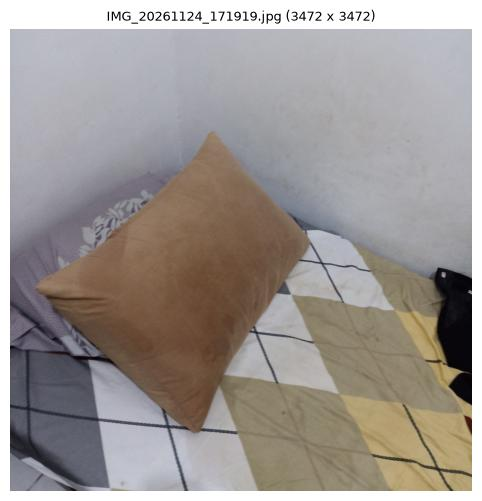

In [3]:
from iiss.data.images import load_image

for path in demo.list_images(IMAGE_PATH)[: 1 if SMOKE else None]:
    image = load_image(path)
    plt.figure(figsize=(6, 6))
    plt.title(f"{path.name} ({image.width} x {image.height})", fontsize=9)
    image.thumbnail((demo.MAX_SIDE, demo.MAX_SIDE))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

## Predict

Keeps the raw predictions (score of at least `demo.MIN_SCORE`) in memory.

In [4]:
photos = demo.list_images(IMAGE_PATH)
photos = photos[:1] if SMOKE else photos
results = [demo.predict_photo(models, p, names) for p in photos]
print(len(results), "photos,", len(models), "models")

1 photos, 3 models


## Show

Fill color = class (same in all panels of a photo). Figures go to `OUT_DIR`.

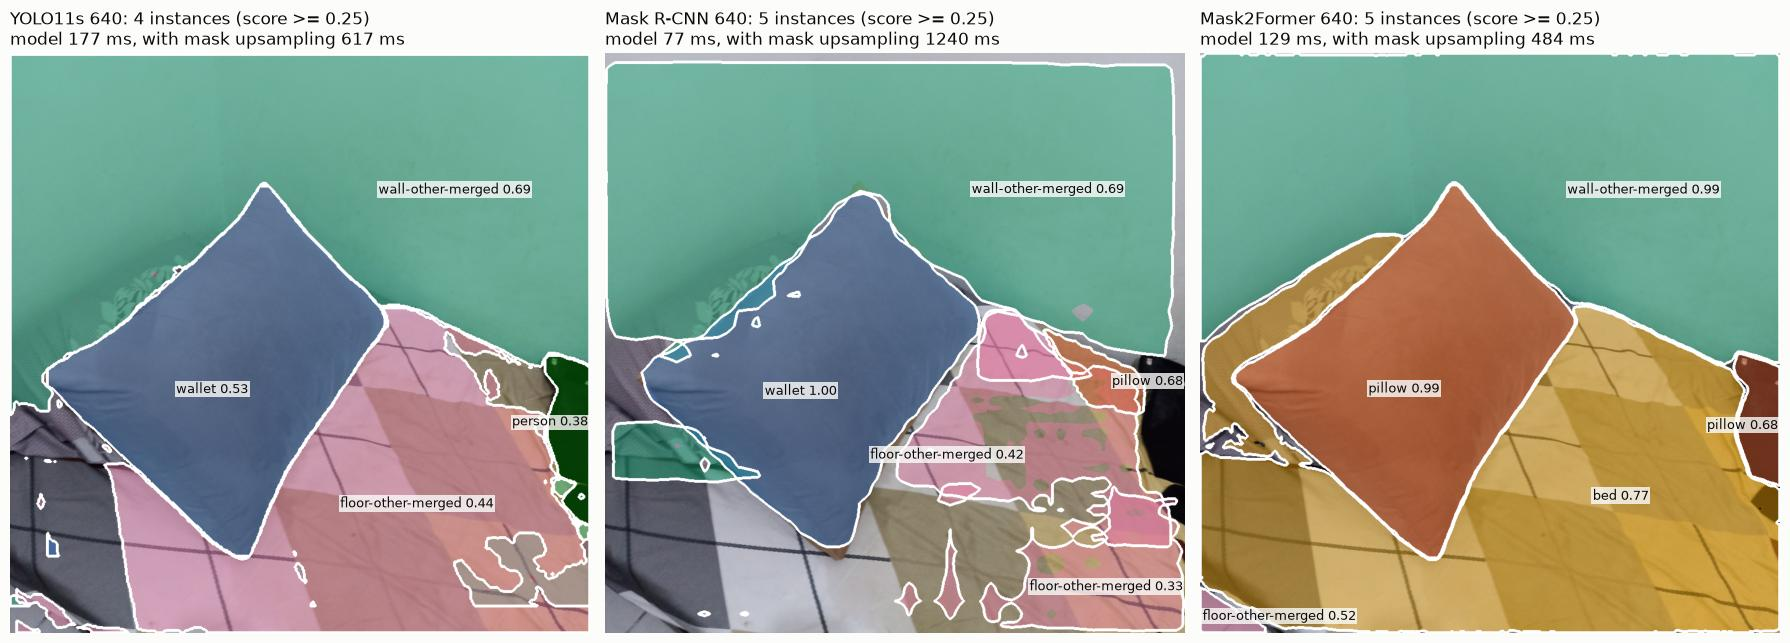

,photo,size,run_id,instances,classes,model_ms,total_ms
0,IMG_20261124_171919.jpg,3472x3472,yolo_s640_seed42,4,"wall-other-merged, wallet, floor-other-merged, person",177,617
1,IMG_20261124_171919.jpg,3472x3472,maskrcnn_s640_seed42,5,"floor-other-merged x2, wallet, wall-other-merged, pillow",77,1240
2,IMG_20261124_171919.jpg,3472x3472,m2f_s640_seed42,5,"pillow x2, wall-other-merged, bed, floor-other-merged",129,484


In [10]:
# THRESHOLD = SCORE_THRESHOLD
THRESHOLD = 0.25

for result in results:
    demo.plot_photo(result, THRESHOLD, OUT_DIR)
    plt.show()
demo.summary_table(results, THRESHOLD)

## Per-class AP

Mask AP x 100 from `results/eval/`, nothing is computed again. Only classes with ground truth in the set; the row `mean` is the reported AP.

In [6]:
AP_RUNS = RUNS  # e.g. ['yolo_s320', 'yolo_s640', 'yolo_s960']
EVAL_SET = "phone"  # valid, test or phone

demo.per_class_ap(AP_RUNS, EVAL_SET)

,n_gt,yolo_s640_seed42,maskrcnn_s640_seed42,m2f_s640_seed42
name,,,,
wall-other-merged,47,19.4,21.3,21.1
table-merged,18,38.2,28.3,16.7
pillow,13,1.3,0.8,34.3
floor-other-merged,12,12.6,9.6,24.7
chair,11,0.0,0.7,9.9
bottle,8,45.3,43.3,62.4
food-other-merged,8,0.0,0.0,0.4
towel,8,0.0,1.4,3.2
bed,7,0.0,0.2,27.4
